In [ ]:
!pip install geopandas shapely rasterio numpy matplotlib pandas fiona

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 50.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fiona]


In [ ]:
from osgeo import gdal

print("GDAL Version:", gdal.VersionInfo("--version"))

GDAL Version: GDAL 3.8.4, released 2024/02/08


In [ ]:
import geopandas as gpd
import numpy as np
import shapely
from osgeo import gdal
import rasterio
import matplotlib.pyplot as plt

print("All six GIS libraries imported successfully!")


All six GIS libraries imported successfully!


In [ ]:
print("GeoPandas:", gpd.__version__)
print("NumPy:", np.__version__)
print("Shapely:", shapely.__version__)
print("GDAL:", gdal.VersionInfo("--version"))
print("Rasterio:", rasterio.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

GeoPandas: 1.2.0
NumPy: 2.4.6
Shapely: 2.2.0
GDAL: GDAL 3.8.4, released 2024/02/08
Rasterio: 1.5.2
Matplotlib: 3.10.0


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataurban.zip to dataurban.zip


In [ ]:
import zipfile
import os

zip_path = "/content/dataurban.zip"

extract_path = "/content/jaipur_gis_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Data extracted successfully!")

Data extracted successfully!


In [ ]:
import geopandas as gpd

roads = gpd.read_file(
    "/content/jaipur_gis_data/New folder/Roads.shp"
)

buildings = gpd.read_file(
    "/content/jaipur_gis_data/New folder/Buildings.shp"
)

parks = gpd.read_file(
    "/content/jaipur_gis_data/New folder/Park.shp"
)

print("All three layers imported successfully!")

All three layers imported successfully!


In [ ]:
# Inspect all three GIS layers

layers = {
    "Roads": roads,
    "Buildings": buildings,
    "Parks": parks
}

for name, gdf in layers.items():

    print("\n==========", name, "==========")

    print("Total features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:")
    print(gdf.geom_type.value_counts())

    print("Columns:")
    print(gdf.columns.tolist())

    print("First 5 records:")
    display(gdf.head())


========== Roads ==========
Total features: 51108
CRS: EPSG:32643
Geometry types:
LineString         51061
MultiLineString       47
Name: count, dtype: int64
Columns:
['fid_1', 'osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'geometry']
First 5 records:


,fid_1,osm_id,code,fclass,name,ref,oneway,maxspeed,layer,bridge,tunnel,geometry
0,515.0,22835306,5112,trunk,None,NH52,F,0,0,F,F,"LINESTRING (579216.866 2966624.15, 579256.894 ..."
1,2019.0,28717241,5112,trunk,Mirza Ismail Road,None,F,0,0,F,F,"LINESTRING (579573.6 2977581.494, 579596.564 2..."
2,2020.0,28717352,5113,primary,Mirza Ismail Road,None,F,0,0,F,F,"LINESTRING (579417.646 2977639.381, 579435.4 2..."
3,2021.0,28717397,5112,trunk,Agra Jaipur Bikaner Road,None,F,0,0,F,F,"LINESTRING (583954.414 2975990.721, 583963.554..."
4,2048.0,28776728,5114,secondary,Amer Road,None,F,0,0,F,F,"LINESTRING (582567.597 2978856.574, 582554.489..."



========== Buildings ==========
Total features: 41079
CRS: EPSG:32643
Geometry types:
Polygon         41077
MultiPolygon        2
Name: count, dtype: int64
Columns:
['fid_1', 'osm_id', 'code', 'fclass', 'name', 'type', 'geometry']
First 5 records:


,fid_1,osm_id,code,fclass,name,type,geometry
0,505.0,86547367,1500,building,Devi Niketan Hotel,None,"POLYGON ((579085.007 2976987.082, 579078.752 2..."
1,624.0,102877521,1500,building,None,None,"POLYGON ((579534.689 2978194.286, 579462.882 2..."
2,1962.0,133268567,1500,building,Income Tax Department,None,"POLYGON ((579881.907 2976359.798, 579868.053 2..."
3,1963.0,133268569,1500,building,None,None,"POLYGON ((579592.951 2976253.677, 579574.916 2..."
4,1964.0,133268570,1500,building,None,None,"POLYGON ((578702.694 2976294.34, 578701.23 297..."



========== Parks ==========
Total features: 733
CRS: EPSG:32643
Geometry types:
Polygon    733
Name: count, dtype: int64
Columns:
['fid_1', 'osm_id', 'code', 'fclass', 'name', 'geometry']
First 5 records:


,fid_1,osm_id,code,fclass,name,geometry
0,92.0,29171977,2204,park,None,"POLYGON ((579789.571 2973883.303, 579726.582 2..."
1,855.0,82111286,2204,park,Subash Nagar Park,"POLYGON ((579225.565 2979714.375, 579163.119 2..."
2,865.0,86547367,2401,hotel,Devi Niketan Hotel,"POLYGON ((579085.007 2976987.082, 579078.752 2..."
3,2178.0,133268541,2204,park,Deer Park,"POLYGON ((579342.006 2976172.714, 579243.421 2..."
4,2179.0,133268542,2204,park,Nehru Park,"POLYGON ((579448.142 2976149.824, 579437.371 2..."


In [ ]:
#check feature classification
print("ROAD CLASSIFICATION")
print(roads["fclass"].value_counts().head(15))

print("\nBUILDING CLASSIFICATION")
print(buildings["fclass"].value_counts().head(15))

print("\nPARK CLASSIFICATION")
print(parks["fclass"].value_counts().head(15))

ROAD CLASSIFICATION
fclass
residential       41320
service            4215
tertiary           2255
footway             920
primary             449
secondary           434
trunk               349
living_street       247
path                240
steps               161
track               124
tertiary_link       113
primary_link         82
trunk_link           61
secondary_link       55
Name: count, dtype: int64

BUILDING CLASSIFICATION
fclass
building    41079
Name: count, dtype: int64

PARK CLASSIFICATION
fclass
park             287
pitch             70
playground        39
water_tower       28
hotel             27
school            26
hospital          21
fountain          17
swimming_pool     16
shelter           15
cafe              14
mall              13
toilet            11
college            9
track              8
Name: count, dtype: int64


In [ ]:
# Extract actual parks

parks_only = parks[
    parks["fclass"] == "park"
].copy()

print("Original places features:", len(parks))
print("Actual park features:", len(parks_only))

Original places features: 733
Actual park features: 287


In [ ]:
#check geometry validation
print("Roads valid:", roads.geometry.is_valid.sum())
print("Buildings valid:", buildings.geometry.is_valid.sum())
print("Parks valid:", parks_only.geometry.is_valid.sum())

Roads valid: 51108
Buildings valid: 41079
Parks valid: 287


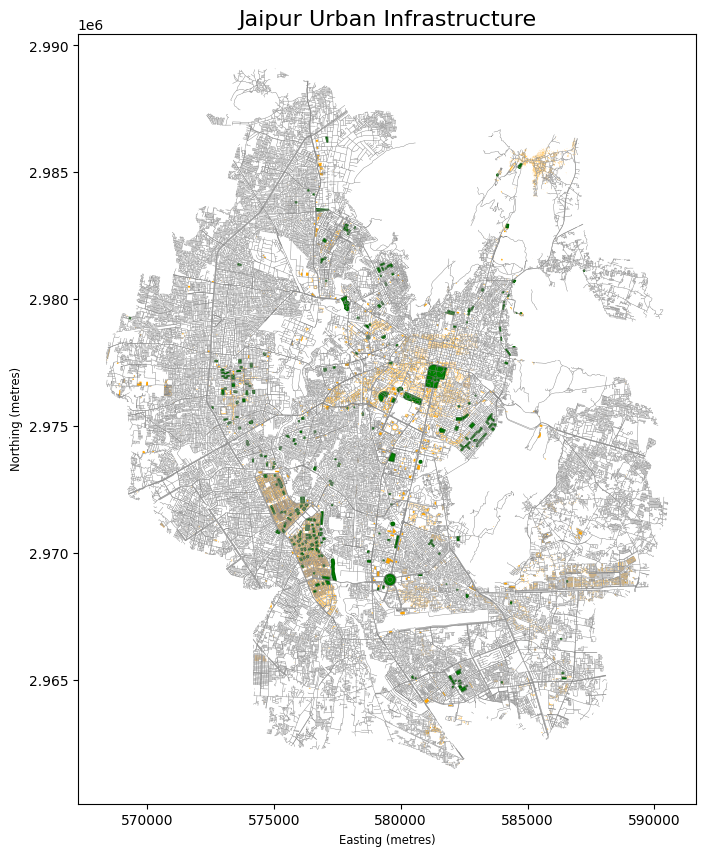

In [ ]:
#visualize all three dataset
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

roads.plot(
    ax=ax,
    color="grey",
    linewidth=0.3
)

buildings.plot(
    ax=ax,
    color="orange",
    edgecolor="none"
)

parks_only.plot(
    ax=ax,
    color="green",
    edgecolor="darkgreen"
)

ax.set_title("Jaipur Urban Infrastructure", fontsize=16)
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

plt.show()

In [ ]:
#inspect the geographical extent for choose smaller area

for name, gdf in {
    "Roads": roads,
    "Buildings": buildings,
    "Parks": parks_only
}.items():

    print("\n", name)
    print("Minimum X, Y:", gdf.total_bounds[:2])
    print("Maximum X, Y:", gdf.total_bounds[2:])




 Roads
Minimum X, Y: [ 568385.70532242 2961494.43346292]
Maximum X, Y: [ 590533.64759671 2989082.14082799]

 Buildings
Minimum X, Y: [ 568408.2093404  2961608.72850207]
Maximum X, Y: [ 589765.89312163 2987743.3399811 ]

 Parks
Minimum X, Y: [ 569304.57631607 2964526.603028  ]
Maximum X, Y: [ 587248.10261108 2986387.09956262]


In [ ]:
# Define study area
#Study area: 4 km × 4 km (16 km²)

from shapely.geometry import box

study_area = box(
    578000,
    2975000,
    582000,
    2979000
)

# Convert study area into GeoDataFrame
study_area_gdf = gpd.GeoDataFrame(
    geometry=[study_area],
    crs="EPSG:32643"
)

# Clip datasets
roads_clip = gpd.clip(roads, study_area_gdf)

buildings_clip = gpd.clip(buildings, study_area_gdf)

parks_clip = gpd.clip(parks_only, study_area_gdf)

# Display results
print("Clipping completed!")

print("Roads:", len(roads_clip))
print("Buildings:", len(buildings_clip))
print("Parks:", len(parks_clip))

Clipping completed!
Roads: 2749
Buildings: 4749
Parks: 20


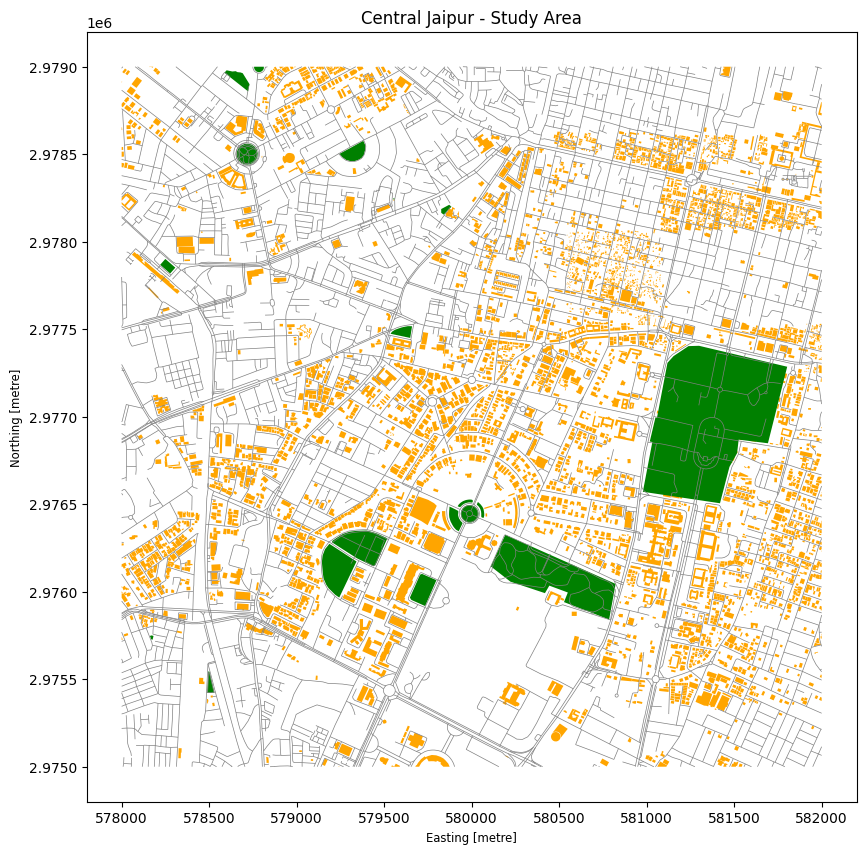

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

roads_clip.plot(ax=ax, color="grey", linewidth=0.5)
buildings_clip.plot(ax=ax, color="orange")
parks_clip.plot(ax=ax, color="green")

ax.set_title("Central Jaipur - Study Area")
ax.set_aspect("equal")

plt.show()

In [ ]:
#calculate building area

# Create a copy of clipped buildings
buildings_analysis = buildings_clip.copy()

# Calculate building area in square metres
buildings_analysis["area_sqm"] = (
    buildings_analysis.geometry.area
)

# Display results
print("Building area calculated successfully!")

display(
    buildings_analysis[
        ["osm_id", "fclass", "area_sqm"]
    ].head(10)
)

Building area calculated successfully!


,osm_id,fclass,area_sqm
31179,824469121,building,381.219805
2814,375062972,building,62.030321
2870,375064422,building,378.691218
2809,375062965,building,2830.930237
2862,375064414,building,250.071375
31760,976749578,building,5025.584821
31159,824469101,building,220.422504
3695,375532221,building,469.691651
3688,375532213,building,253.184961
3683,375532208,building,222.609489


In [ ]:
#find five largest buildings

largest_buildings = buildings_analysis.nlargest(
    5, "area_sqm"
)

display(
    largest_buildings[
        ["osm_id", "area_sqm"]
    ]
)

,osm_id,area_sqm
3381,5583670,17190.205449
12,133276648,14844.432947
35,170097363,12433.278923
30254,757545711,9607.150052
34547,1380330723,9258.862340


In [ ]:
#road length calculation
#individual road length

# Create a copy of clipped roads
roads_analysis = roads_clip.copy()

# Calculate road length in metres
roads_analysis["length_m"] = (
    roads_analysis.geometry.length
)

print("Road length calculated successfully!")

display(
    roads_analysis[
        ["osm_id", "fclass", "length_m"]
    ].head(10)
)

Road length calculated successfully!


,osm_id,fclass,length_m
27740,757545713,primary,36.583599
42373,1209958452,footway,128.684733
39938,1095069158,service,39.021294
1346,230816769,service,296.162696
1349,230816773,service,114.141357
26310,665583713,service,366.443464
1353,230816779,service,114.504095
27438,753703772,secondary,454.444354
28973,865674746,footway,329.478257
28974,865674747,footway,462.648607


In [ ]:
#calculate road length by road type

road_summary = (
    roads_analysis
    .groupby("fclass")["length_m"]
    .sum()
    .reset_index()
)

road_summary["length_km"] = (
    road_summary["length_m"] / 1000
)

road_summary = road_summary.sort_values(
    by="length_km",
    ascending=False
)

display(road_summary)

,fclass,length_m,length_km
7,residential,178942.747184,178.942747
10,service,63959.333641,63.959334
12,tertiary,53351.107609,53.351108
5,primary,26692.132613,26.692133
1,footway,11411.308625,11.411309
8,secondary,9644.852862,9.644853
15,trunk,8522.474090,8.522474
3,path,5054.767296,5.054767
2,living_street,3436.765012,3.436765
13,tertiary_link,1652.790269,1.652790


In [ ]:
#total road length

total_road_length = road_summary["length_m"].sum()

print("Total Road Length (km):",
      round(total_road_length / 1000, 2))

Total Road Length (km): 367.01


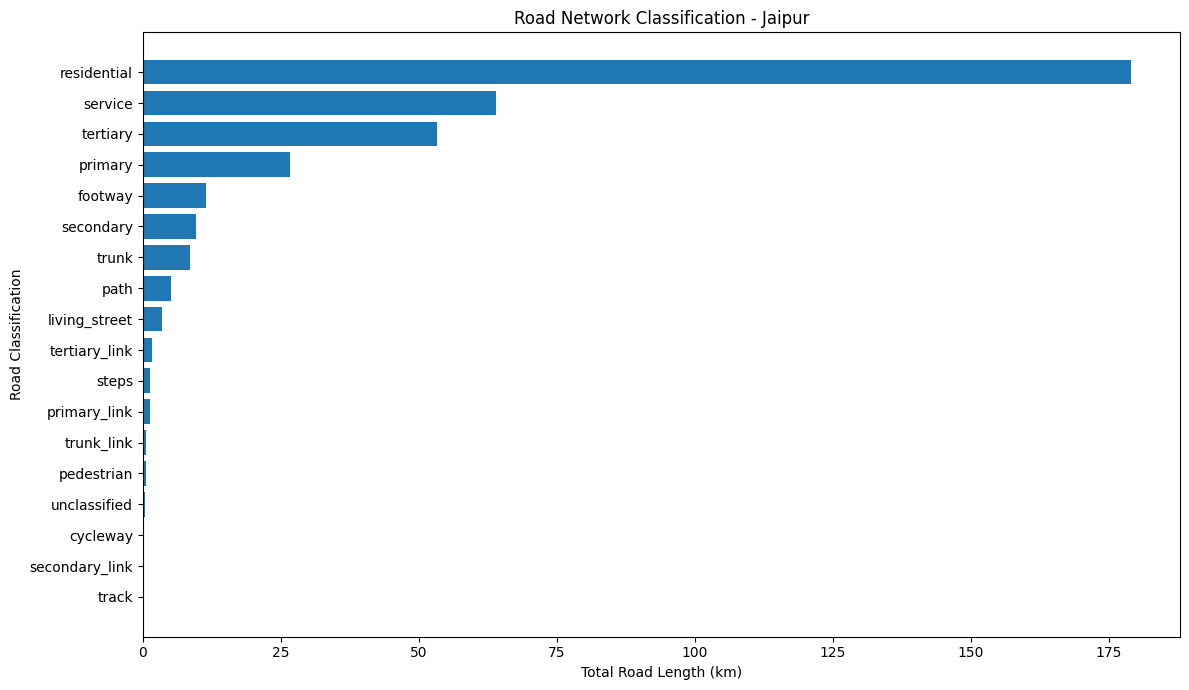

In [ ]:
#visualize road classification

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    road_summary["fclass"],
    road_summary["length_km"]
)

plt.xlabel("Total Road Length (km)")
plt.ylabel("Road Classification")

plt.title(
    "Road Network Classification - Jaipur"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
#Create a 100-metre road buffer

# Create a 100-metre buffer around each road
road_buffers = roads_analysis.geometry.buffer(100)

# Merge overlapping buffer polygons into one geometry
road_buffer_geom = road_buffers.union_all()

# Convert the result into a GeoDataFrame
road_buffer = gpd.GeoDataFrame(
    {"buffer_distance_m": [100]},
    geometry=[road_buffer_geom],
    crs=roads_analysis.crs
)

print("100-metre road buffer created successfully!")
print("Buffer CRS:", road_buffer.crs)

100-metre road buffer created successfully!
Buffer CRS: EPSG:32643


In [ ]:
#Identify buildings within 100 metres of roads

# Check which buildings intersect the road buffer
buildings_analysis["within_100m_of_road"] = (
    buildings_analysis.geometry.intersects(road_buffer_geom)
)

# Count buildings inside and outside the buffer
building_proximity = (
    buildings_analysis["within_100m_of_road"].value_counts()
)

print(building_proximity)

within_100m_of_road
True     4747
False       2
Name: count, dtype: int64


In [ ]:
#calculate the percentage

total_buildings = len(buildings_analysis)

buildings_near_roads = (
    buildings_analysis["within_100m_of_road"].sum()
)

percentage_near_roads = (
    buildings_near_roads / total_buildings
) * 100

print("Total Buildings:", total_buildings)
print("Buildings within 100m of roads:", buildings_near_roads)
print("Percentage:", round(percentage_near_roads, 2), "%")

Total Buildings: 4749
Buildings within 100m of roads: 4747
Percentage: 99.96 %


In [ ]:
#park area analysis

# Create a copy of the park layer
parks_analysis = parks_clip.copy()

# Calculate the area of each park in square metres
parks_analysis["area_sqm"] = parks_analysis.geometry.area

# Convert square metres into hectares
parks_analysis["area_hectares"] = (
    parks_analysis["area_sqm"] / 10000
)

# Calculate total park area
total_park_area = parks_analysis["area_sqm"].sum()

# Calculate total area in hectares
total_park_hectares = total_park_area / 10000

print("Total Parks:", len(parks_analysis))
print("Total Park Area (sq. m):", round(total_park_area, 2))
print("Total Park Area (hectares):", round(total_park_hectares, 2))

Total Parks: 20
Total Park Area (sq. m): 814702.47
Total Park Area (hectares): 81.47


In [ ]:
# find five largest park

# Sort parks by area in descending order
largest_parks = parks_analysis.nlargest(
    5, "area_sqm"
)

# Display the five largest parks
display(
    largest_parks[
        ["osm_id", "area_sqm", "area_hectares"]
    ]
)

,osm_id,area_sqm,area_hectares
48,272783001,486546.869956,48.654687
115,442860839,147378.647879,14.737865
4,133268542,38311.080406,3.831108
3,133268541,36184.308938,3.618431
97,394056630,30406.509154,3.040651


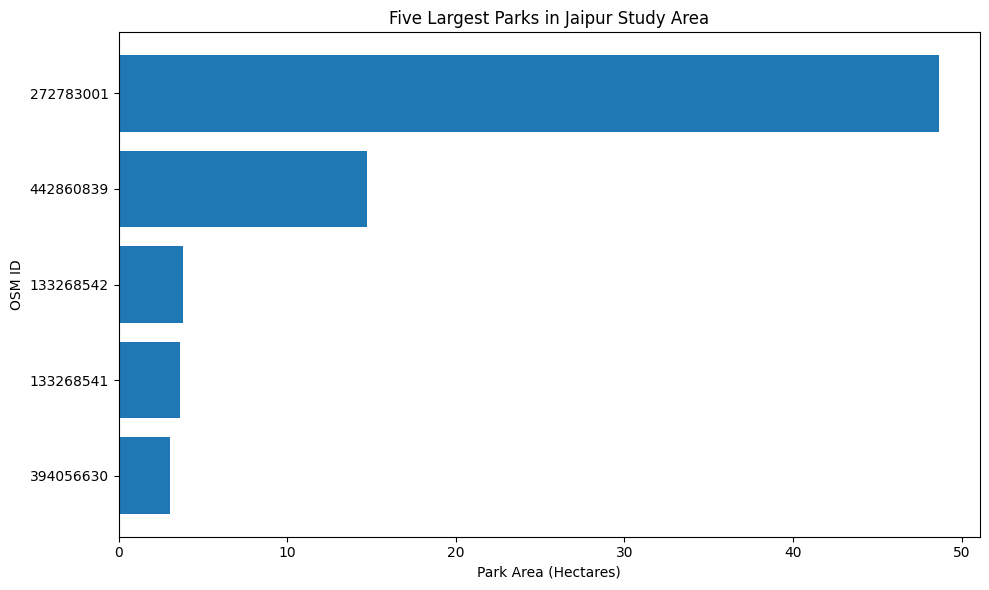

In [ ]:
# bar chart for park area

import matplotlib.pyplot as plt

# Sort largest parks for horizontal plotting
plot_parks = largest_parks.sort_values(
    by="area_hectares",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_parks["osm_id"].astype(str),
    plot_parks["area_hectares"]
)

plt.xlabel("Park Area (Hectares)")
plt.ylabel("OSM ID")
plt.title("Five Largest Parks in Jaipur Study Area")

plt.tight_layout()
plt.show()

In [ ]:
#Raster analysis(rasterio + numpy)

import numpy as np
import rasterio

from rasterio.transform import from_bounds
from rasterio.features import rasterize

# Define raster resolution
pixel_size = 10

# Get study area boundaries
minx, miny, maxx, maxy = study_area.bounds

# Calculate raster dimensions
width = int((maxx - minx) / pixel_size)
height = int((maxy - miny) / pixel_size)

# Create raster transformation
transform = from_bounds(
    minx, miny, maxx, maxy,
    width, height
)

print("Raster width:", width)
print("Raster height:", height)
print("Pixel size:", pixel_size, "metres")
print("Total pixels:", width * height)

Raster width: 400
Raster height: 400
Pixel size: 10 metres
Total pixels: 160000


In [ ]:
#convert building polygons into raster

# Convert building geometries into raster shapes
building_shapes = (
    (geometry, 1)
    for geometry in buildings_analysis.geometry
)

# Rasterize building polygons
building_raster = rasterize(
    shapes=building_shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype="uint8"
)

print("Rasterization completed!")
print("Raster shape:", building_raster.shape)
print("Data type:", building_raster.dtype)
print("Unique values:", np.unique(building_raster))

Rasterization completed!
Raster shape: (400, 400)
Data type: uint8
Unique values: [0 1]


In [ ]:
#Calculate building-covered area using NumPy

# Count building pixels
building_pixels = np.count_nonzero(building_raster == 1)

# Count empty pixels
empty_pixels = np.count_nonzero(building_raster == 0)

# Calculate area of one pixel
pixel_area = pixel_size * pixel_size

# Calculate total building-covered area
building_area = building_pixels * pixel_area

# Convert to hectares
building_area_hectares = building_area / 10000

# Calculate percentage coverage
building_percentage = (
    building_pixels / building_raster.size
) * 100

print("Building pixels:", building_pixels)
print("Empty pixels:", empty_pixels)
print("Total pixels:", building_raster.size)

print("Building area (sq. m):", building_area)
print("Building area (hectares):", round(building_area_hectares, 2))
print("Building coverage:", round(building_percentage, 2), "%")

Building pixels: 18000
Empty pixels: 142000
Total pixels: 160000
Building area (sq. m): 1800000
Building area (hectares): 180.0
Building coverage: 11.25 %


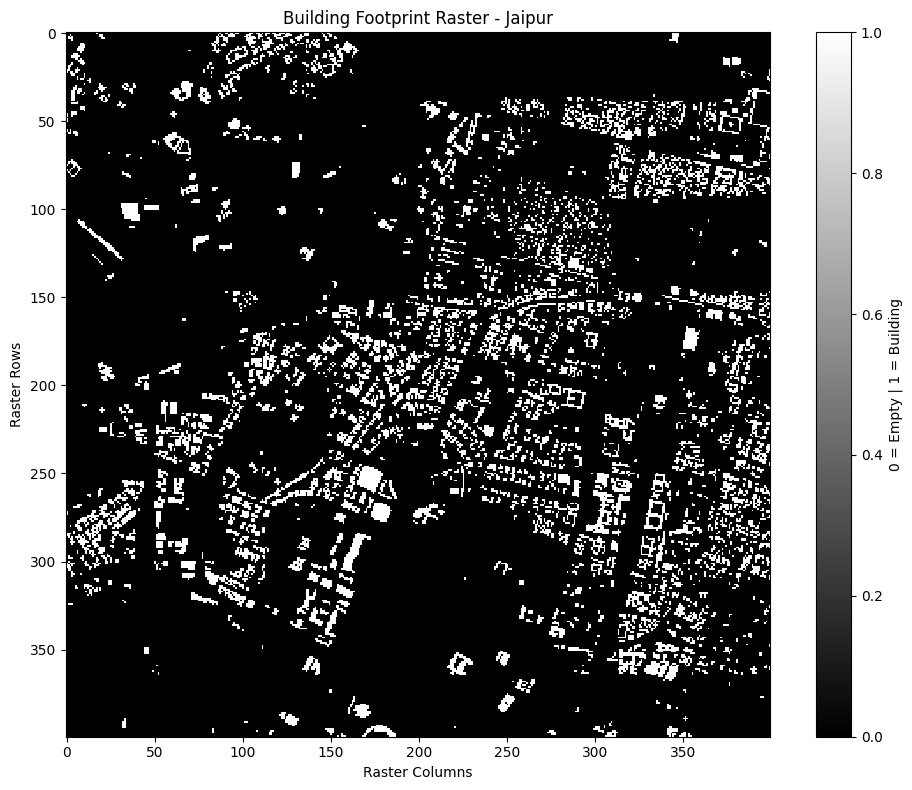

In [ ]:
#visualise building raster

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    building_raster,
    cmap="grey",
    interpolation="nearest"
)

plt.title("Building Footprint Raster - Jaipur")
plt.xlabel("Raster Columns")
plt.ylabel("Raster Rows")

plt.colorbar(
    label="0 = Empty | 1 = Building"
)

plt.tight_layout()
plt.show()

In [ ]:
#export raster as Geotiff

# Define output file
raster_output = "/content/jaipur_building_raster.tif"

# Save raster as GeoTIFF
with rasterio.open(
    raster_output,
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=1,
    dtype=building_raster.dtype,
    crs=buildings_analysis.crs,
    transform=transform
) as dst:

    dst.write(building_raster, 1)

print("GeoTIFF exported successfully!")
print("Output:", raster_output)

GeoTIFF exported successfully!
Output: /content/jaipur_building_raster.tif


In [ ]:
with rasterio.open(raster_output) as src:

    print("Raster verified successfully!")
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes)

Raster verified successfully!
Width: 400
Height: 400
Bands: 1
CRS: EPSG:32643
Resolution: (10.0, 10.0)
Data type: ('uint8',)


In [ ]:
#Inspect the GeoTIFF using GDAL

from osgeo import gdal

# Open GeoTIFF using GDAL
dataset = gdal.Open(raster_output)

# Get raster information
print("Raster width:", dataset.RasterXSize)
print("Raster height:", dataset.RasterYSize)
print("Number of bands:", dataset.RasterCount)

# Get geotransform
print("GeoTransform:", dataset.GetGeoTransform())

# Get projection
print("Projection:")
print(dataset.GetProjection())

# Read raster band
band = dataset.GetRasterBand(1)

print("Data type:", gdal.GetDataTypeName(band.DataType))
print("Minimum value:", band.GetMinimum())
print("Maximum value:", band.GetMaximum())

Raster width: 400
Raster height: 400
Number of bands: 1
GeoTransform: (578000.0, 10.0, 0.0, 2979000.0, 0.0, -10.0)
Projection:
PROJCS["WGS 84 / UTM zone 43N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32643"]]
Data type: Byte
Minimum value: None
Maximum value: None


/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


In [ ]:
#calculate raster statistics using GDAL

from osgeo import gdal

gdal.UseExceptions()

dataset = gdal.Open(raster_output)

band = dataset.GetRasterBand(1)

# Calculate raster statistics
stats = band.ComputeStatistics(False)

print("Minimum:", stats[0])
print("Maximum:", stats[1])
print("Mean:", stats[2])
print("Standard Deviation:", stats[3])

Minimum: 0.0
Maximum: 1.0
Mean: 0.1125
Standard Deviation: 0.3159806164941134


In [ ]:
#export the results in gpkg

# Export roads
roads_analysis.to_file(
    "/content/jaipur_urban_analysis.gpkg",
    layer="roads",
    driver="GPKG"
)

# Export buildings with calculated area
buildings_analysis.to_file(
    "/content/jaipur_urban_analysis.gpkg",
    layer="buildings",
    driver="GPKG"
)

# Export parks with calculated area
parks_analysis.to_file(
    "/content/jaipur_urban_analysis.gpkg",
    layer="parks",
    driver="GPKG"
)

# Export road buffer
road_buffer.to_file(
    "/content/jaipur_urban_analysis.gpkg",
    layer="road_buffer_100m",
    driver="GPKG"
)

print("All vector layers exported successfully!")


All vector layers exported successfully!


In [ ]:
#verify

import fiona

layers = fiona.listlayers(
    "/content/jaipur_urban_analysis.gpkg"
)

print("Available GeoPackage layers:")

for layer in layers:
    print(layer)

Available GeoPackage layers:
roads
buildings
parks
road_buffer_100m
